In [1]:
import kagglehub
path = kagglehub.dataset_download("jessicali9530/celeba-dataset")

Using Colab cache for faster access to the 'celeba-dataset' dataset.


In [2]:
import os, random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import torchvision.utils as vutils

IMAGE_SIZE  = 64
BATCH_SIZE  = 128
LATENT_DIM  = 100
EPOCHS      = 15
LR          = 2e-4
MAX_IMAGES  = 50000

random.seed(42); torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

OUT_DIR = "outputs"
os.makedirs(f"{OUT_DIR}/samples", exist_ok=True)
os.makedirs(f"{OUT_DIR}/checkpoints", exist_ok=True)

Device: cuda


In [3]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

IMAGE_DIR = os.path.join(path, "img_align_celeba", "img_align_celeba")

transform = transforms.Compose([
    transforms.CenterCrop(148),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = datasets.ImageFolder(root=os.path.dirname(IMAGE_DIR), transform=transform)
if MAX_IMAGES:
    dataset = Subset(dataset, range(MAX_IMAGES))

dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=2, pin_memory=True, drop_last=True)

print("Number of Images:", len(dataset))
print("Number of Batches:", len(dataloader))
print("Image Shape:", dataset[0][0].shape)

Number of Images: 50000
Number of Batches: 390
Image Shape: torch.Size([3, 64, 64])


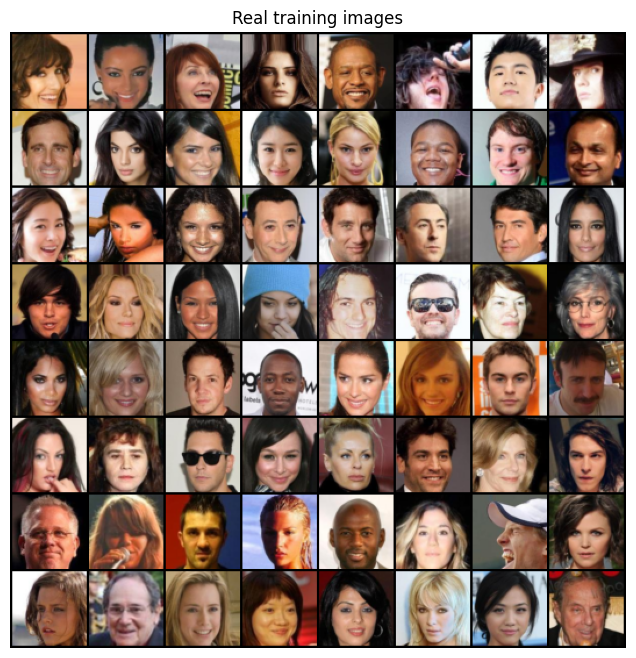

In [4]:
real_batch, _ = next(iter(dataloader))
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Real training images")
plt.imshow(np.transpose(
    vutils.make_grid(real_batch[:64], nrow=8, padding=2, normalize=True, value_range=(-1, 1)), (1, 2, 0)))
plt.show()

In [5]:
class Generator(nn.Module):
    def __init__(self, nz=LATENT_DIM, ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf*8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf*8), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*8, ngf*4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf*4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf*4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*4, ndf*8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf*8), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf*8, 1, 4, 1, 0, bias=False),
            # no Sigmoid: the model outputs logits
        )
    def forward(self, x):
        return self.net(x).view(-1)


def weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

G = Generator().to(device); G.apply(weights_init)
D = Discriminator().to(device); D.apply(weights_init)

print("Generator params:    ", sum(p.numel() for p in G.parameters()))
print("Discriminator params:", sum(p.numel() for p in D.parameters()))

Generator params:     3576704
Discriminator params: 2765568


In [6]:
criterion = nn.BCEWithLogitsLoss()
optG = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=device)
REAL_LABEL, FAKE_LABEL = 0.9, 0.0

g_losses, d_losses = [], []

[1/15][0/390] D loss: 1.917 | G loss: 6.078 | D(x): 0.62 | D(G(z)): 0.65
[1/15][100/390] D loss: 0.594 | G loss: 6.348 | D(x): 0.91 | D(G(z)): 0.07
[1/15][200/390] D loss: 1.580 | G loss: 2.710 | D(x): 0.31 | D(G(z)): 0.01
[1/15][300/390] D loss: 0.737 | G loss: 5.211 | D(x): 0.86 | D(G(z)): 0.27


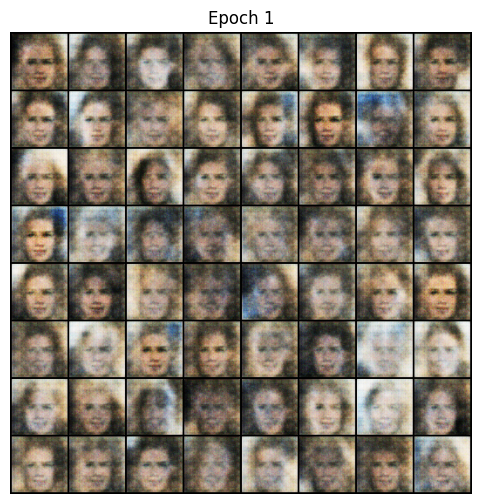

[2/15][0/390] D loss: 1.005 | G loss: 7.424 | D(x): 0.83 | D(G(z)): 0.41
[2/15][100/390] D loss: 2.822 | G loss: 3.640 | D(x): 0.16 | D(G(z)): 0.00
[2/15][200/390] D loss: 0.559 | G loss: 4.427 | D(x): 0.80 | D(G(z)): 0.10
[2/15][300/390] D loss: 0.619 | G loss: 3.265 | D(x): 0.68 | D(G(z)): 0.06


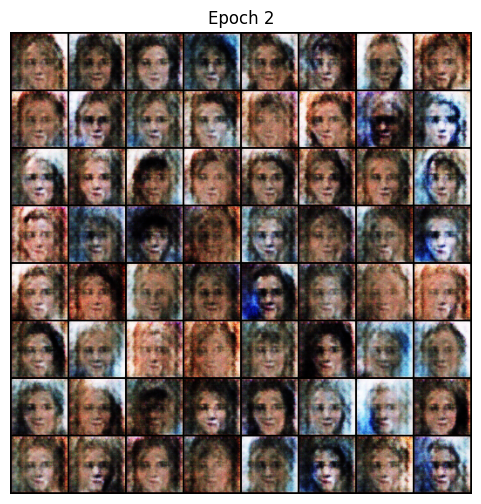

[3/15][0/390] D loss: 0.543 | G loss: 4.302 | D(x): 0.86 | D(G(z)): 0.10
[3/15][100/390] D loss: 0.601 | G loss: 2.582 | D(x): 0.70 | D(G(z)): 0.07
[3/15][200/390] D loss: 1.305 | G loss: 1.265 | D(x): 0.33 | D(G(z)): 0.02
[3/15][300/390] D loss: 0.611 | G loss: 5.303 | D(x): 0.84 | D(G(z)): 0.15


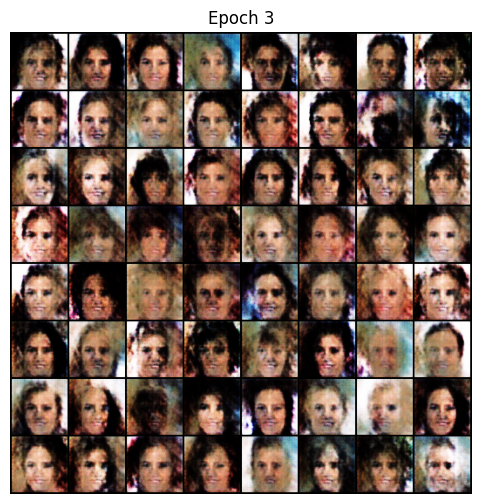

[4/15][0/390] D loss: 0.530 | G loss: 3.234 | D(x): 0.80 | D(G(z)): 0.09
[4/15][100/390] D loss: 0.766 | G loss: 3.589 | D(x): 0.74 | D(G(z)): 0.19
[4/15][200/390] D loss: 0.721 | G loss: 2.937 | D(x): 0.61 | D(G(z)): 0.05
[4/15][300/390] D loss: 0.633 | G loss: 3.685 | D(x): 0.70 | D(G(z)): 0.08


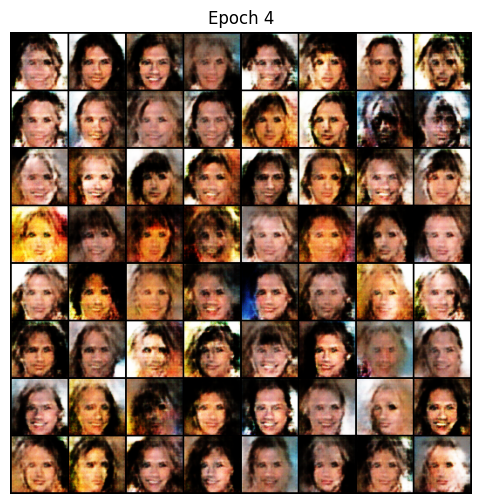

[5/15][0/390] D loss: 0.607 | G loss: 3.666 | D(x): 0.68 | D(G(z)): 0.05
[5/15][100/390] D loss: 0.711 | G loss: 3.408 | D(x): 0.77 | D(G(z)): 0.18
[5/15][200/390] D loss: 0.726 | G loss: 4.852 | D(x): 0.87 | D(G(z)): 0.26
[5/15][300/390] D loss: 0.589 | G loss: 4.411 | D(x): 0.87 | D(G(z)): 0.18


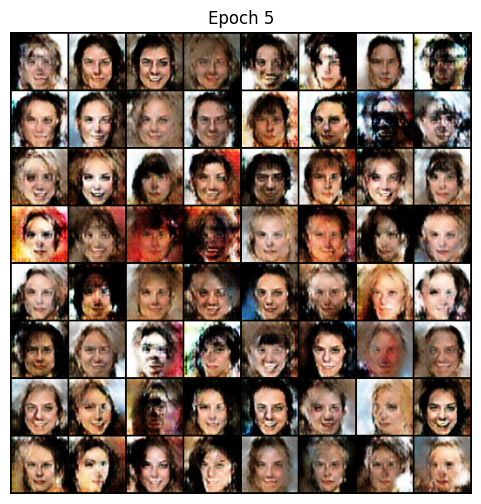

[6/15][0/390] D loss: 0.687 | G loss: 3.732 | D(x): 0.78 | D(G(z)): 0.20
[6/15][100/390] D loss: 0.674 | G loss: 4.578 | D(x): 0.81 | D(G(z)): 0.19
[6/15][200/390] D loss: 0.776 | G loss: 2.321 | D(x): 0.61 | D(G(z)): 0.12
[6/15][300/390] D loss: 1.016 | G loss: 5.487 | D(x): 0.87 | D(G(z)): 0.42


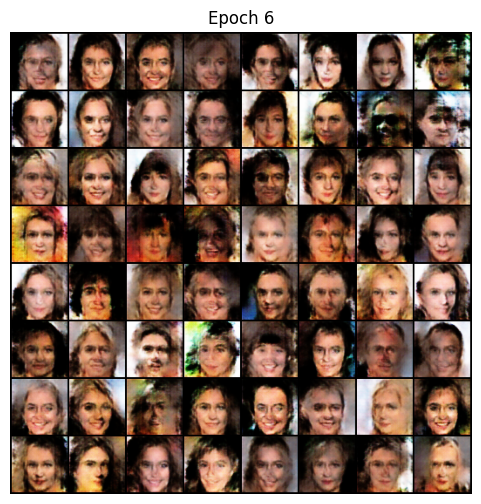

[7/15][0/390] D loss: 0.648 | G loss: 2.734 | D(x): 0.69 | D(G(z)): 0.10
[7/15][100/390] D loss: 0.727 | G loss: 4.667 | D(x): 0.85 | D(G(z)): 0.28
[7/15][200/390] D loss: 1.178 | G loss: 1.755 | D(x): 0.51 | D(G(z)): 0.30
[7/15][300/390] D loss: 0.654 | G loss: 2.736 | D(x): 0.67 | D(G(z)): 0.12


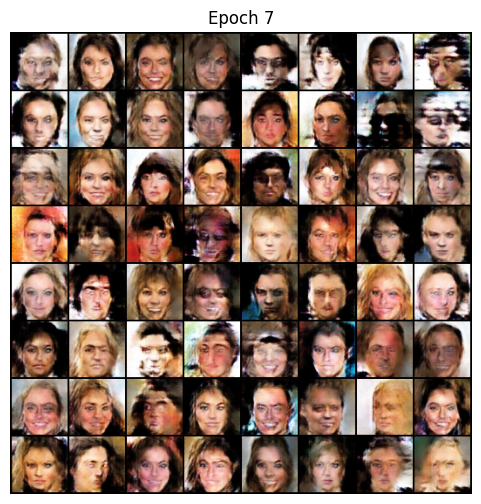

[8/15][0/390] D loss: 0.655 | G loss: 2.454 | D(x): 0.72 | D(G(z)): 0.15
[8/15][100/390] D loss: 0.769 | G loss: 1.990 | D(x): 0.57 | D(G(z)): 0.08
[8/15][200/390] D loss: 0.679 | G loss: 3.628 | D(x): 0.80 | D(G(z)): 0.22
[8/15][300/390] D loss: 0.964 | G loss: 1.572 | D(x): 0.45 | D(G(z)): 0.06


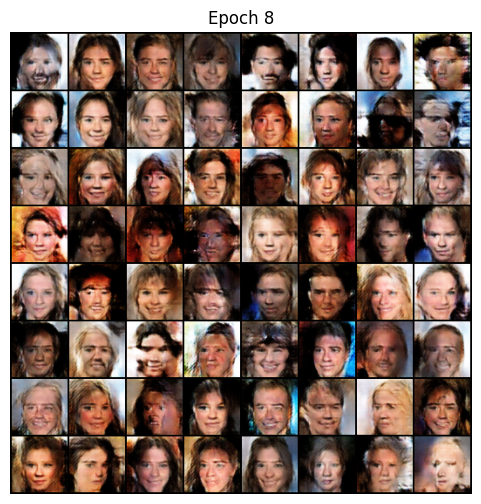

[9/15][0/390] D loss: 0.622 | G loss: 3.441 | D(x): 0.75 | D(G(z)): 0.14
[9/15][100/390] D loss: 0.789 | G loss: 2.679 | D(x): 0.76 | D(G(z)): 0.27
[9/15][200/390] D loss: 0.730 | G loss: 2.940 | D(x): 0.78 | D(G(z)): 0.24
[9/15][300/390] D loss: 0.649 | G loss: 2.689 | D(x): 0.76 | D(G(z)): 0.18


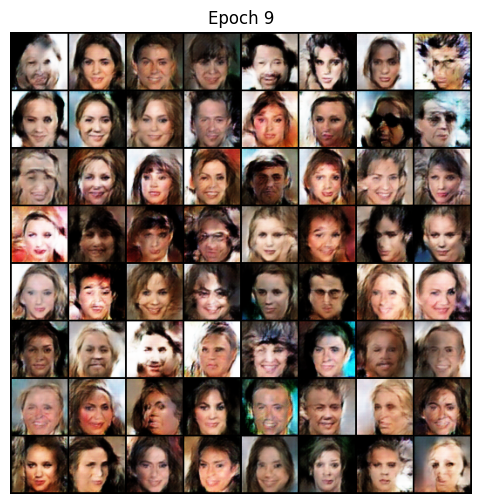

[10/15][0/390] D loss: 0.752 | G loss: 2.813 | D(x): 0.76 | D(G(z)): 0.26
[10/15][100/390] D loss: 0.635 | G loss: 3.588 | D(x): 0.88 | D(G(z)): 0.23
[10/15][200/390] D loss: 0.632 | G loss: 2.502 | D(x): 0.69 | D(G(z)): 0.13
[10/15][300/390] D loss: 0.625 | G loss: 2.595 | D(x): 0.75 | D(G(z)): 0.16


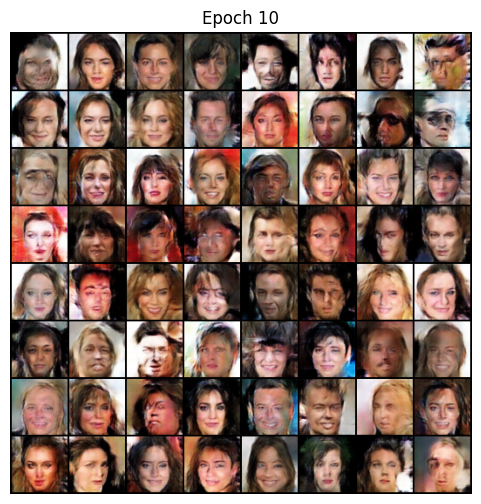

[11/15][0/390] D loss: 0.708 | G loss: 3.162 | D(x): 0.78 | D(G(z)): 0.25
[11/15][100/390] D loss: 1.020 | G loss: 1.259 | D(x): 0.40 | D(G(z)): 0.03
[11/15][200/390] D loss: 0.904 | G loss: 3.173 | D(x): 0.76 | D(G(z)): 0.35
[11/15][300/390] D loss: 1.878 | G loss: 0.873 | D(x): 0.16 | D(G(z)): 0.02


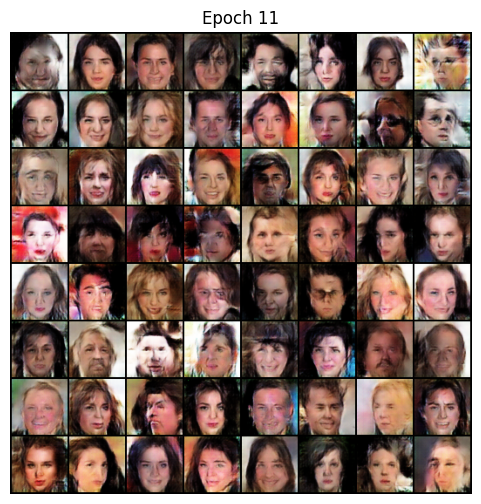

[12/15][0/390] D loss: 1.090 | G loss: 1.867 | D(x): 0.40 | D(G(z)): 0.06
[12/15][100/390] D loss: 0.640 | G loss: 3.119 | D(x): 0.82 | D(G(z)): 0.22
[12/15][200/390] D loss: 0.723 | G loss: 1.919 | D(x): 0.57 | D(G(z)): 0.07
[12/15][300/390] D loss: 0.907 | G loss: 2.444 | D(x): 0.63 | D(G(z)): 0.25


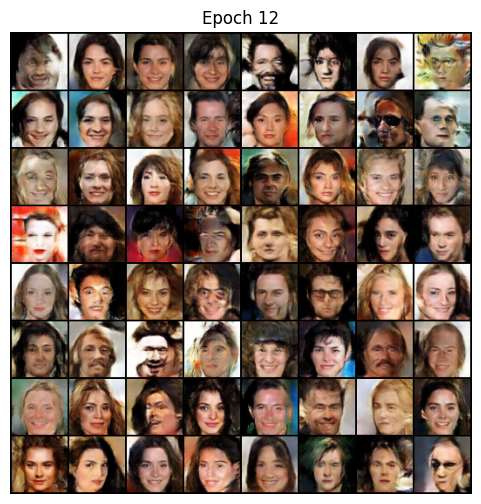

[13/15][0/390] D loss: 0.602 | G loss: 2.640 | D(x): 0.82 | D(G(z)): 0.19
[13/15][100/390] D loss: 0.764 | G loss: 2.147 | D(x): 0.68 | D(G(z)): 0.21
[13/15][200/390] D loss: 1.012 | G loss: 3.585 | D(x): 0.86 | D(G(z)): 0.46
[13/15][300/390] D loss: 1.378 | G loss: 1.163 | D(x): 0.28 | D(G(z)): 0.04


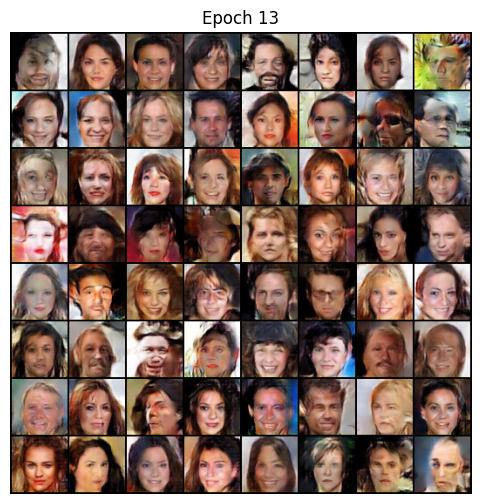

[14/15][0/390] D loss: 0.982 | G loss: 1.549 | D(x): 0.41 | D(G(z)): 0.03
[14/15][100/390] D loss: 0.612 | G loss: 3.035 | D(x): 0.85 | D(G(z)): 0.21
[14/15][200/390] D loss: 0.711 | G loss: 2.024 | D(x): 0.62 | D(G(z)): 0.12
[14/15][300/390] D loss: 0.959 | G loss: 5.006 | D(x): 0.92 | D(G(z)): 0.43


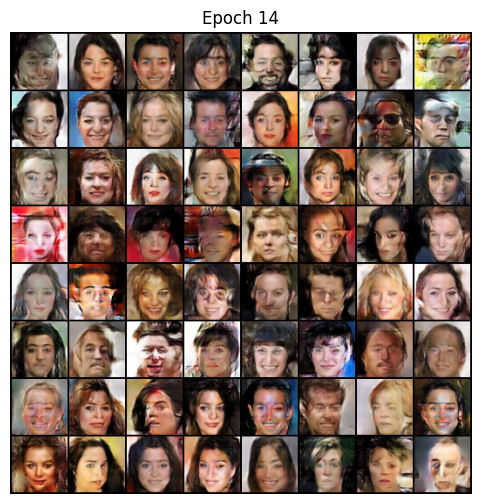

[15/15][0/390] D loss: 0.600 | G loss: 2.650 | D(x): 0.74 | D(G(z)): 0.15
[15/15][100/390] D loss: 1.120 | G loss: 1.403 | D(x): 0.37 | D(G(z)): 0.07
[15/15][200/390] D loss: 0.769 | G loss: 2.752 | D(x): 0.83 | D(G(z)): 0.31
[15/15][300/390] D loss: 0.607 | G loss: 2.825 | D(x): 0.73 | D(G(z)): 0.13


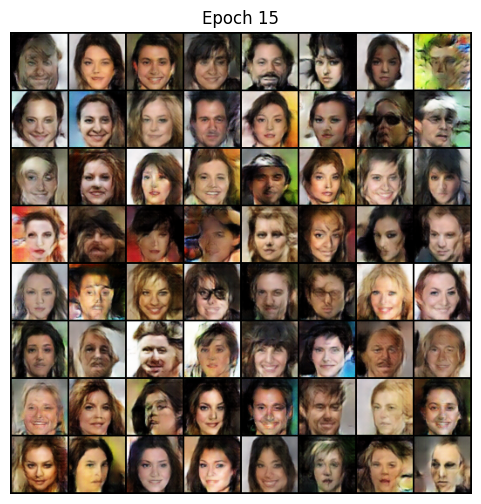

In [7]:
for epoch in range(1, EPOCHS + 1):
    for i, (real, _) in enumerate(dataloader):
        real = real.to(device)
        b = real.size(0)

        # Train Discriminator
        D.zero_grad()
        out_real = D(real)  # logits
        loss_real = criterion(out_real, torch.full((b,), REAL_LABEL, device=device))

        z = torch.randn(b, LATENT_DIM, 1, 1, device=device)
        fake = G(z)
        out_fake = D(fake.detach())  # logits
        loss_fake = criterion(out_fake, torch.full((b,), FAKE_LABEL, device=device))

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optD.step()

        # Train Generator
        G.zero_grad()
        out = D(fake)  # logits
        loss_G = criterion(out, torch.ones(b, device=device))
        loss_G.backward()
        optG.step()

        g_losses.append(loss_G.item())
        d_losses.append(loss_D.item())

        if i % 100 == 0:
            dx = torch.sigmoid(out_real).mean().item()
            dgz = torch.sigmoid(out_fake).mean().item()
            print(f"[{epoch}/{EPOCHS}][{i}/{len(dataloader)}] "
                  f"D loss: {loss_D.item():.3f} | G loss: {loss_G.item():.3f} | "
                  f"D(x): {dx:.2f} | D(G(z)): {dgz:.2f}")

    # save samples from the same fixed noise
    G.eval()
    with torch.no_grad():
        samples = G(fixed_noise).cpu()
    G.train()
    vutils.save_image(samples, f"{OUT_DIR}/samples/epoch_{epoch:03d}.png",
                      nrow=8, normalize=True, value_range=(-1, 1), padding=2)

    # a separate checkpoint for every epoch
    torch.save(G.state_dict(), f"{OUT_DIR}/checkpoints/generator_epoch_{epoch:03d}.pth")
    torch.save(D.state_dict(), f"{OUT_DIR}/checkpoints/discriminator_latest.pth")

    plt.figure(figsize=(6, 6)); plt.axis("off"); plt.title(f"Epoch {epoch}")
    plt.imshow(np.transpose(vutils.make_grid(samples, nrow=8, padding=2, normalize=True, value_range=(-1, 1)), (1, 2, 0)))
    plt.show()

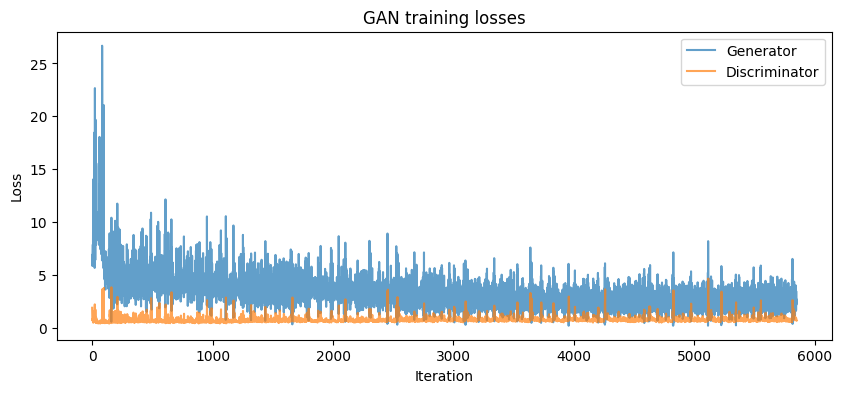

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(g_losses, label="Generator", alpha=0.7)
plt.plot(d_losses, label="Discriminator", alpha=0.7)
plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.title("GAN training losses")
plt.legend()
plt.savefig(f"{OUT_DIR}/loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

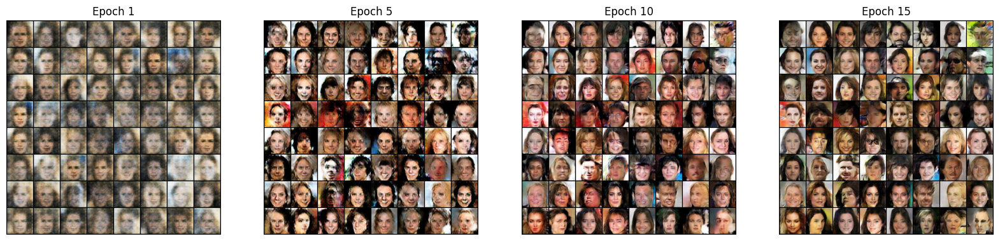

In [9]:
from PIL import Image
picks = sorted({1, max(1, EPOCHS // 3), max(1, 2 * EPOCHS // 3), EPOCHS})
fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 5))
for ax, e in zip(axes, picks):
    ax.imshow(Image.open(f"{OUT_DIR}/samples/epoch_{e:03d}.png"))
    ax.set_title(f"Epoch {e}"); ax.axis("off")
plt.savefig(f"{OUT_DIR}/progress_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

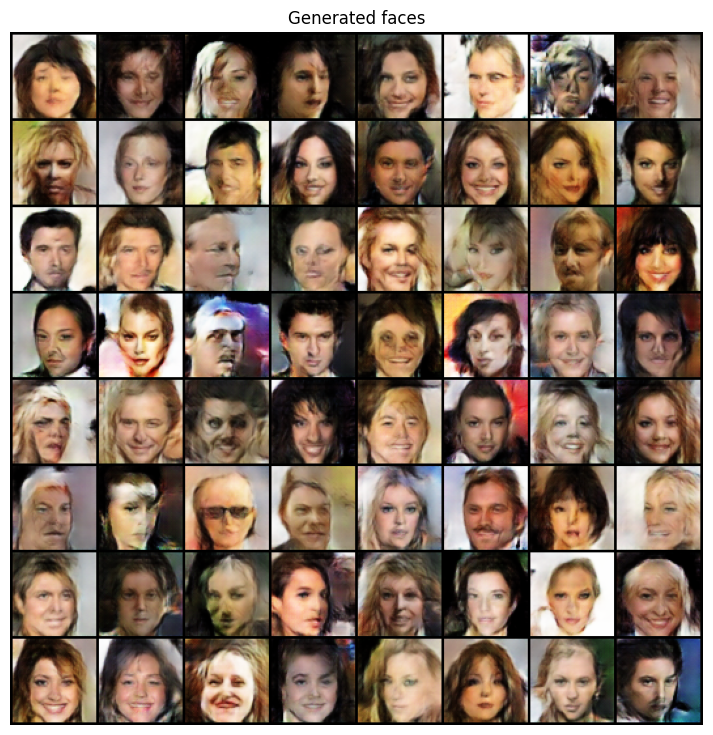

In [10]:
G.eval()
with torch.no_grad():
    final = G(torch.randn(64, LATENT_DIM, 1, 1, device=device)).cpu()
vutils.save_image(final, f"{OUT_DIR}/final_faces.png", nrow=8, normalize=True, value_range=(-1, 1), padding=2)

plt.figure(figsize=(9, 9)); plt.axis("off"); plt.title("Generated faces")
plt.imshow(np.transpose(vutils.make_grid(final, nrow=8, padding=2, normalize=True, value_range=(-1, 1)), (1, 2, 0)))
plt.show()